In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# RF-Guided Iterative Antimalarial Generation

**Pipeline:**  
LLM generation (10 molecules/iter) → RDKit validity → scaffold veto → MW filter (200–900) → SA Score (≤ 4.5)  
→ Tanimoto novelty (max sim ≤ 0.6 vs ALL seen) → OCL descriptor calc → AMCS filter  
→ **RF-1 scoring** (P(active) ≥ 0.5) → label & save all molecules  
→ **Prompt steering**: top-5 actives + top-3 near-misses fed to next iteration  
→ **Exploration burst** every 100 iterations (ban top-5 active scaffolds)  
→ **Scaffold diversity guard** within each batch

**Key changes from zero-shot notebook:**
- 10 molecules per iteration × 1000 iterations
- Lipinski Ro5 removed; replaced by MW range 200–900
- RF-1 model scores every molecule — label stored in CSV (actives AND inactives kept)
- Strategy A prompt steering: best actives → positive examples, near-misses → negative examples
- P(active) threshold fixed at 0.5 throughout (no adaptive ramp)
- Tanimoto guard covers ALL molecules seen (active + inactive) → no duplicates across iterations
- Scaffold diversity check per batch; exploration burst every 100 iterations
- Murcko scaffold frequency tracking


In [ ]:
# ── Install dependencies ──────────────────────────────────────────────────
!pip install openai rdkit pandas --quiet

import subprocess
subprocess.run(['npm', 'install', 'openchemlib', '--prefix', '/tmp/ocl'],
               check=True, capture_output=True)
print('openchemlib installed.')

openchemlib installed.


In [ ]:
# ── Imports ───────────────────────────────────────────────────────────────
import os, re, json, pickle, subprocess
import numpy as np
import pandas as pd
from collections import defaultdict

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem
from rdkit.Chem.Scaffolds import MurckoScaffold

try:
    from rdkit.Avalon import pyAvalonTools
    AVALON_AVAILABLE = True
    print('Avalon fingerprints: available')
except ImportError:
    AVALON_AVAILABLE = False
    print('WARNING: Avalon not available — falling back to RDKit topological FP.')

try:
    from rdkit.Chem import RDConfig
    import sys
    sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score'))
    import sascorer
    print('SA scorer: RDKit contrib')
except Exception:
    try:
        import sascorer
        print('SA scorer: PyPI package')
    except ImportError:
        sascorer = None
        print('WARNING: sascorer not found — using approximation.')

from openai import OpenAI
import getpass

openrouter_api_key = getpass.getpass('Paste your OpenRouter API key and press Enter: ')
client = OpenAI(api_key=openrouter_api_key, base_url='https://openrouter.ai/api/v1')
MODEL = 'anthropic/claude-3-5-haiku'
print('Client ready.')

Avalon fingerprints: available
SA scorer: RDKit contrib
Paste your OpenRouter API key and press Enter: ··········
Client ready.


In [ ]:
# ── Configuration ─────────────────────────────────────────────────────────
N_ITERATIONS        = 1000         # total LLM calls
N_PER_ITER          = 10           # molecules generated per iteration
OVERGENERATE_FACTOR = 4            # ask LLM for 4× to compensate filter attrition

MW_MIN              = 200          # molecular weight range (replaces Lipinski)
MW_MAX              = 900
SA_THRESHOLD        = 4.5
SIM_THRESHOLD       = 0.6          # Tanimoto max similarity vs ALL seen molecules
RF_ACTIVE_THRESHOLD = 0.5          # fixed P(active) cut-off throughout

TOP_ACTIVES_IN_PROMPT  = 5         # best active SMILES fed as positive examples
TOP_NEARMISS_IN_PROMPT = 3         # near-miss SMILES fed as negative examples
EXPLORE_EVERY          = 100       # exploration burst period
TOP_SCAFFOLD_BAN       = 5         # scaffolds banned during exploration burst
SCAFFOLD_DIVERSITY_MAX = 4         # max molecules sharing one Murcko scaffold per batch

OUTPUT_CSV           = 'rf_guided_antimalarials.csv'
RF_MODEL_PATH        = '/content/drive/MyDrive/antimalarial_project/rf1_antimalarial_model.pkl'   # saved from RF training notebook
AVALON_NBITS         = 1024

print('Configuration loaded.')
print(f'  MW range          : {MW_MIN}–{MW_MAX}')
print(f'  SA threshold      : ≤ {SA_THRESHOLD}')
print(f'  Tanimoto threshold: ≤ {SIM_THRESHOLD}')
print(f'  RF threshold      : P(active) ≥ {RF_ACTIVE_THRESHOLD} (fixed)')
print(f'  Iterations        : {N_ITERATIONS} × {N_PER_ITER} molecules')
print(f'  Exploration burst : every {EXPLORE_EVERY} iterations')

Configuration loaded.
  MW range          : 200–900
  SA threshold      : ≤ 4.5
  Tanimoto threshold: ≤ 0.6
  RF threshold      : P(active) ≥ 0.5 (fixed)
  Iterations        : 1000 × 10 molecules
  Exploration burst : every 100 iterations


In [ ]:
# ── Load RF-1 model bundle ────────────────────────────────────────────────
# The model bundle is saved by the RF training notebook as rf1_antimalarial_model.pkl
# It contains: model, scaler, fingerprint type, n_bits, descriptors list, apd_threshold

with open(RF_MODEL_PATH, 'rb') as f:
    bundle = pickle.load(f)

rf_model      = bundle['model']
rf_scaler     = bundle['scaler']
rf_n_bits     = bundle.get('n_bits', AVALON_NBITS)
rf_desc_names = bundle.get('descriptors', ['MW', 'TPSA', 'cLogP', 'AromaticRings', 'BaN'])

print(f'RF-1 model loaded from: {RF_MODEL_PATH}')
print(f'  Features   : Avalon {rf_n_bits} bits + {rf_desc_names}')
print(f'  n_features : {bundle.get("n_features", "unknown")}')
test_m = bundle.get('test_metrics', {})
if test_m:
    print(f'  Test AUROC : {test_m.get("AUROC", "n/a"):.4f}')
    print(f'  Test Acc   : {test_m.get("Accuracy", "n/a"):.4f}')

RF-1 model loaded from: /content/drive/MyDrive/antimalarial_project/rf1_antimalarial_model.pkl
  Features   : Avalon 1024 bits + ['MW', 'TPSA', 'cLogP', 'AromaticRings', 'BaN']
  n_features : 1029
  Test AUROC : 0.9792
  Test Acc   : 0.9315


In [ ]:
# ── RF scoring helper ─────────────────────────────────────────────────────
# Replicates the exact feature-building from the RF training notebook:
#   X = [Avalon FP (1024 bits) | StandardScaler(MW, TPSA, cLogP, AromaticRings, BaN)]

def calc_avalon_fp(mol, n_bits=1024):
    """Avalon fingerprint as float32 numpy array."""
    if AVALON_AVAILABLE:
        from rdkit.Avalon import pyAvalonTools
        fp = pyAvalonTools.GetAvalonFP(mol, nBits=n_bits)
    else:
        fp = Chem.RDKFingerprint(mol, fpSize=n_bits)
    arr = np.zeros(fp.GetNumBits(), dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


def rf_score_molecules(rows_with_descriptors, scaler, model, n_bits=1024):
    """
    Score a list of OCL descriptor dicts with the RF model.

    Each row must have keys: Structure, molecularWeight, topologicalSurfaceArea,
    cLogP, aromaticRingCount, basicNitrogenCount.

    Returns the same list with added keys:
        rf_p_active  : float  — P(active) from RF
        rf_label     : str    — 'Active' if P(active) >= RF_ACTIVE_THRESHOLD else 'Inactive'
    """
    scored = []
    for row in rows_with_descriptors:
        smi = row.get('Structure', '')
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            row['rf_p_active'] = 0.0
            row['rf_label']    = 'Inactive'
            scored.append(row)
            continue
        try:
            fp = calc_avalon_fp(mol, n_bits=n_bits)
        except Exception:
            row['rf_p_active'] = 0.0
            row['rf_label']    = 'Inactive'
            scored.append(row)
            continue

        # Descriptor vector: [MW, TPSA, cLogP, AromaticRings, BaN]
        desc = np.array([
            row.get('molecularWeight',        0.0),
            row.get('topologicalSurfaceArea',  0.0),
            row.get('cLogP',                  0.0),
            row.get('aromaticRingCount',       0.0),
            row.get('basicNitrogenCount',      0.0),
        ], dtype=np.float32).reshape(1, -1)

        desc_scaled = scaler.transform(desc)          # apply training scaler
        X = np.hstack([fp.reshape(1, -1), desc_scaled])  # (1, 1029)

        p_active = float(model.predict_proba(X)[0, 1])
        row['rf_p_active'] = round(p_active, 4)
        row['rf_label']    = 'Active' if p_active >= RF_ACTIVE_THRESHOLD else 'Inactive'
        scored.append(row)
    return scored

print('RF scoring helper loaded.')

RF scoring helper loaded.


In [ ]:
# ── LLM helper ───────────────────────────────────────────────────────────
def call_llm(system_prompt, user_prompt, model=MODEL, temperature=0.9):
    response = client.chat.completions.create(
        model=model, temperature=temperature,
        messages=[{'role': 'system', 'content': system_prompt},
                  {'role': 'user',   'content': user_prompt}]
    )
    return response.choices[0].message.content


def extract_valid_smiles(llm_response_text):
    candidates = re.findall(r'[A-Za-z][A-Za-z0-9@+\-\[\]\(\)=#$\/\\%\.]+',
                            llm_response_text)
    common_words = {'The','This','These','Here','Note','Each','For',
                    'With','From','SMILES','InChI'}
    valid = []
    for c in candidates:
        if len(c) < 3 or c in common_words: continue
        if not re.search(r'[0-9@+\-\[\]\(\)=#$\/\\%\.]', c): continue
        mol = Chem.MolFromSmiles(c)
        if mol: valid.append(Chem.MolToSmiles(mol))
    seen, uniq = set(), []
    for s in valid:
        if s not in seen: seen.add(s); uniq.append(s)
    return uniq


# ── Scaffold veto ─────────────────────────────────────────────────────────
QUINOLINE_SMARTS   = 'c1ccc2ncccc2c1'
QUINAZOLINE_SMARTS = 'c1ccc2ncncc2c1'
FORBIDDEN_PATTERNS = [Chem.MolFromSmarts(s)
                      for s in (QUINOLINE_SMARTS, QUINAZOLINE_SMARTS)]

def veto_forbidden_scaffolds(smiles_list):
    kept = []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None: continue
        if any(mol.HasSubstructMatch(p) for p in FORBIDDEN_PATTERNS): continue
        kept.append(smi)
    return kept


# ── MW range filter (replaces Lipinski Ro5) ───────────────────────────────
def filter_mw_range(smiles_list, mw_min=MW_MIN, mw_max=MW_MAX):
    kept, discarded = [], 0
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None: discarded += 1; continue
        mw = Descriptors.MolWt(mol)
        if mw_min <= mw <= mw_max:
            kept.append(smi)
        else:
            discarded += 1
    print(f'[MW filter] Kept {len(kept)}, discarded {discarded} '
          f'(MW outside {mw_min}–{mw_max})')
    return kept


# ── SA Score filter ───────────────────────────────────────────────────────
def _get_sa_score(mol):
    try:
        if sascorer:
            return sascorer.calculateScore(mol)
        n_rings  = rdMolDescriptors.CalcNumRings(mol)
        n_stereo = len(Chem.FindMolChiralCenters(mol, includeUnassigned=True))
        fsp3     = rdMolDescriptors.CalcFractionCSP3(mol)
        score    = 1.0 + 0.5*n_stereo + 0.3*max(0, n_rings-2) + (1-fsp3)*0.5
        return min(score, 6.0)
    except Exception:
        return None

def filter_sa_score(smiles_list, threshold=SA_THRESHOLD):
    kept, discarded = [], 0
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None: discarded += 1; continue
        sa = _get_sa_score(mol)
        if sa is None or sa > threshold:
            discarded += 1
        else:
            kept.append(smi)
    print(f'[SA filter] Kept {len(kept)}, discarded {discarded} (SA > {threshold})')
    return kept


# ── Tanimoto novelty filter (Morgan FP, covers ALL seen molecules) ─────────
def _morgan_fp(smi, radius=2, nbits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    return AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=nbits)

def filter_tanimoto_novelty(candidate_smiles, ref_fps, threshold=SIM_THRESHOLD):
    """
    Keep candidates whose max Tanimoto similarity to ref_fps is <= threshold.
    ref_fps covers ALL molecules seen so far (active + inactive).
    Adds fingerprints of accepted molecules to ref_fps in-place.
    Returns (kept_smiles, updated_ref_fps).
    """
    if not ref_fps:
        kept, new_fps = [], []
        for smi in candidate_smiles:
            fp = _morgan_fp(smi)
            if fp is not None:
                kept.append(smi)
                new_fps.append(fp)
        return kept, ref_fps + new_fps

    kept, new_fps, discarded = [], [], 0
    for smi in candidate_smiles:
        fp = _morgan_fp(smi)
        if fp is None:
            discarded += 1
            continue
        sims = DataStructs.BulkTanimotoSimilarity(fp, ref_fps)
        if max(sims) > threshold:
            discarded += 1
        else:
            kept.append(smi)
            new_fps.append(fp)
            ref_fps.append(fp)   # update library immediately

    print(f'[Tanimoto] Kept {len(kept)}, discarded {discarded} '
          f'(max sim > {threshold}; ref library = {len(ref_fps)} fps)')
    return kept, ref_fps


print('Filter functions loaded.')

Filter functions loaded.


In [ ]:
# ── OpenChemLib-JS descriptor calculation ─────────────────────────────────
# Identical JS script from the RF training notebook.
# Outputs: Structure, cLogP, molecularWeight, topologicalSurfaceArea,
#          hDonorCount, hAcceptorCount, rotatableBondCount,
#          basicNitrogenCount, aromaticRingCount

_OCL_JS_SCRIPT = r"""
import OCL from '/tmp/ocl/node_modules/openchemlib/dist/openchemlib.js';
const { Molecule, MoleculeProperties } = OCL;

function getFakeOxoCount(mol, atom) {
  let n = 0;
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {
    const no = mol.getAtomicNo(mol.getConnAtom(atom, i));
    if (mol.getConnBondOrder(atom, i) === 2 && (no===7||no===8||no===16)) n++;
  }
  return n;
}

function isStabilized(mol, atom, twice) {
  let found = false;
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {
    const bond = mol.getConnBond(atom, i);
    if (!mol.isAromaticBond(bond) && mol.getConnBondOrder(atom, i) === 1) {
      const conn = mol.getConnAtom(atom, i);
      if (!mol.isAromaticAtom(conn) &&
          ((mol.getAtomicNo(conn)===6 && getFakeOxoCount(mol,conn)===1) ||
           (mol.getAtomicNo(conn)===16 && getFakeOxoCount(mol,conn)===2))) {
        if (found || !twice) return true;
        found = true;
      }
    }
  }
  return false;
}

function isVinylogFakeOxo(mol, atom) {
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {
    if (mol.getConnBondOrder(atom, i) !== 1) {
      const conn = mol.getConnAtom(atom, i);
      for (let j = 0; j < mol.getConnAtoms(conn); j++)
        if (mol.getConnBondOrder(conn,j)===1 && getFakeOxoCount(mol,mol.getConnAtom(conn,j))!==0)
          return true;
    }
  }
  return false;
}

function isBasicNitrogen(mol, atom) {
  if (mol.getAtomicNo(atom) !== 7) return false;
  if (mol.getAtomCharge(atom) !== 0) return false;
  if (mol.getConnAtoms(atom) + mol.getAtomPi(atom) > 3) return false;
  if (mol.isAromaticAtom(atom)) {
    if (mol.getAtomPi(atom) !== 1) return false;
    if (mol.getAtomRingCount(atom, 7) !== 1) return false;
    const rc = mol.getRingSet();
    for (let r = 0; r < rc.getSize(); r++) {
      if (!rc.isAtomMember(r, atom)) continue;
      const sz = rc.getRingSize(r);
      if (sz !== 5 && sz !== 6) { break; }
      const ring = rc.getRingAtoms(r);
      const R = Array.from({length:sz}, (_,i)=>ring[i]);
      let ni = R.indexOf(atom);
      let opi, mi;
      if (sz === 5) {
        opi = [R[ni-1<0?ni+4:ni-1], R[ni-4<0?ni+1:ni-4]];
        mi  = [R[ni-2<0?ni+3:ni-2], R[ni-3<0?ni+2:ni-3]];
      } else {
        opi = [R[ni-1<0?ni+5:ni-1], R[ni-3<0?ni+3:ni-3], R[ni-5<0?ni+1:ni-5]];
        mi  = [R[ni-2<0?ni+4:ni-2], R[ni-4<0?ni+2:ni-4]];
      }
      let ec = 0;
      for (let i=0; i<R.length; i++)
        if (atom!==R[i] && mol.getAtomicNo(R[i])===7 && mol.getAtomPi(R[i])===1) ec--;
      for (let i=0; i<opi.length; i++) {
        let exoAtom=-1, exoBond=-1;
        for (let j=0; j<mol.getConnAtoms(opi[i]); j++) {
          if (!mol.isAromaticBond(mol.getConnBond(opi[i],j))) {
            exoAtom=mol.getConnAtom(opi[i],j); exoBond=mol.getConnBond(opi[i],j); break;
          }
        }
        if (exoAtom !== -1) {
          if (mol.getAtomicNo(exoAtom)===7 && mol.getAtomPi(exoAtom)===0
              && (mol.getConnAtoms(exoAtom)+mol.getAtomPi(exoAtom)<=3)
              && !isStabilized(mol,exoAtom,false)) { ec++; continue; }
          if (mol.getAtomicNo(exoAtom)===8 && mol.getConnAtoms(exoAtom)===1) { ec+=2; continue; }
          if (mol.isAromaticBond(exoBond)) {
            for (let s=0; s<rc.getSize(); s++) {
              if (rc.isAromatic(s) && rc.isAtomMember(s,exoAtom)) {
                const ra=rc.getRingAtoms(s);
                for (let j=0; j<rc.getRingSize(s); j++)
                  if (mol.getAtomicNo(ra[j])===7 && mol.getAtomPi(ra[j])===1) { ec--; break; }
                break;
              }
            }
          }
        }
      }
      for (let i=0; i<mi.length; i++) {
        let exoAtom=-1;
        for (let j=0; j<mol.getConnAtoms(mi[i]); j++)
          if (!mol.isAromaticBond(mol.getConnBond(mi[i],j))) exoAtom=mol.getConnAtom(mi[i],j);
        if (mol.getAtomicNo(mi[i])===6) {
          if (exoAtom!==-1 && getFakeOxoCount(mol,exoAtom)!==0) ec--;
        } else if (mol.getAtomicNo(mi[i])===7) {
          if (mol.getAtomPi(mi[i])===0 &&
              (exoAtom===-1 || (!mol.isAromaticAtom(exoAtom) && getFakeOxoCount(mol,exoAtom)===0)))
            ec++;
        }
      }
      return ec > 0;
    }
    return false;
  }
  if (mol.getAtomPi(atom) > 1) return false;
  if (mol.getAtomPi(atom) === 1) {
    let imineC=-1, sc=0;
    for (let i=0; i<mol.getConnAtoms(atom); i++) {
      const conn=mol.getConnAtom(atom,i);
      if (mol.getConnBondOrder(atom,i)===2) {
        if (mol.getAtomicNo(conn)!==6) return false;
        imineC=conn; continue;
      }
      if (mol.getAtomicNo(conn)===8) return false;
      if (mol.getAtomicNo(conn)===7) { sc--; if (isStabilized(mol,conn,false)) sc--; continue; }
      if (mol.isAromaticAtom(conn)) sc--;
    }
    if (imineC===-1) return false;
    let arNC=0;
    for (let i=0; i<mol.getConnAtoms(imineC); i++) {
      if (mol.getConnBondOrder(imineC,i)===1) {
        const conn=mol.getConnAtom(imineC,i);
        if (getFakeOxoCount(mol,conn)!==0) return false;
        if (mol.isAromaticAtom(conn)) arNC++;
        if (mol.getAtomicNo(conn)===7 && !isStabilized(mol,conn,true)) sc++;
        if (mol.getAtomicNo(conn)===8||mol.getAtomicNo(conn)===16) sc--;
      }
    }
    if (arNC===2) sc--;
    return sc >= 0;
  }
  for (let i=0; i<mol.getConnAtoms(atom); i++) {
    const conn=mol.getConnAtom(atom,i);
    if (mol.isAromaticAtom(conn)) return false;
    if (mol.getAtomicNo(conn)!==6) return false;
    if (getFakeOxoCount(mol,conn)!==0) return false;
    if (mol.getAtomPi(conn)!==0 && isVinylogFakeOxo(mol,conn)) return false;
  }
  return true;
}

function countBasicNitrogens(mol) {
  let n=0;
  for (let i=0; i<mol.getAllAtoms(); i++) if (isBasicNitrogen(mol,i)) n++;
  return n;
}

const smilesList = JSON.parse(process.argv[2]);
const results = [];
for (const smi of smilesList) {
  try {
    const mol = Molecule.fromSmiles(smi);
    mol.ensureHelperArrays(255);
    const props = new MoleculeProperties(mol);
    const formula = mol.getMolecularFormula();
    results.push({
      Structure:              smi,
      cLogP:                  parseFloat(props.logP.toFixed(3)),
      molecularWeight:        parseFloat(formula.relativeWeight.toFixed(3)),
      topologicalSurfaceArea: parseFloat(props.polarSurfaceArea.toFixed(3)),
      hDonorCount:            props.donorCount,
      hAcceptorCount:         props.acceptorCount,
      rotatableBondCount:     props.rotatableBondCount,
      basicNitrogenCount:     countBasicNitrogens(mol),
      aromaticRingCount:      mol.getAromaticRingCount(),
    });
  } catch(e) {
    results.push({Structure: smi, error: e.message});
  }
}
process.stdout.write(JSON.stringify(results));
"""

def run_ocl_calc(smiles_list):
    """Calculate OCL descriptors. Returns list of dicts."""
    if not smiles_list:
        return []
    with open('/tmp/_ocl_calc.mjs', 'w') as f:
        f.write(_OCL_JS_SCRIPT)
    result = subprocess.run(
        ['node', '/tmp/_ocl_calc.mjs', json.dumps(smiles_list)],
        capture_output=True, text=True, timeout=300
    )
    if result.returncode != 0:
        print(f'[OCL] Node.js error: {result.stderr[:400]}')
        return []
    rows = json.loads(result.stdout)
    valid = [r for r in rows if 'error' not in r]
    if len(rows) - len(valid):
        print(f'[OCL] Skipped {len(rows)-len(valid)} unparseable SMILES.')
    print(f'[OCL] Descriptors calculated for {len(valid)} molecules.')
    return valid


# ── AMCS filter (no Lipinski) ─────────────────────────────────────────────
DW_COL = {
    'basic_n': 'basicNitrogenCount',
    'arom_r':  'aromaticRingCount',
    'clogp':   'cLogP',
    'tpsa':    'topologicalSurfaceArea',
}

def filter_amcs(rows, min_amcs=3):
    """
    AMCS filter only (Lipinski removed).
    Requires: basicN >= 1, aromaticRings >= 2, cLogP >= 2, TPSA <= 80.
    At least min_amcs of the 4 criteria must be satisfied.
    """
    def _f(row, key, fallback=0.0):
        try: return float(row.get(DW_COL[key], fallback))
        except (ValueError, TypeError): return fallback

    filtered = []
    for row in rows:
        amcs = sum([
            _f(row, 'basic_n') >= 1,
            _f(row, 'arom_r')  >= 2,
            _f(row, 'clogp')   >= 2,
            _f(row, 'tpsa')    <= 80,
        ])
        if amcs >= min_amcs:
            row['AMCS_passes'] = amcs
            filtered.append(row)
    print(f'[AMCS] {len(filtered)} / {len(rows)} passed (≥{min_amcs}/4 criteria)')
    return filtered


print('OCL + AMCS filter loaded.')

OCL + AMCS filter loaded.


In [ ]:
# ── Scaffold utilities ────────────────────────────────────────────────────

def get_murcko_scaffold(smi):
    """Return canonical Murcko scaffold SMILES or None."""
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    try:
        scaffold = MurckoScaffold.GetScaffoldForMol(mol)
        return Chem.MolToSmiles(scaffold)
    except Exception:
        return None


def check_scaffold_diversity(smiles_batch, max_per_scaffold=SCAFFOLD_DIVERSITY_MAX):
    """
    Within-batch scaffold diversity check.
    If more than max_per_scaffold molecules share the same Murcko scaffold,
    keep only the first max_per_scaffold from that scaffold.
    Returns (filtered_smiles, diversity_warning: bool).
    """
    scaffold_counts = defaultdict(int)
    kept = []
    for smi in smiles_batch:
        sc = get_murcko_scaffold(smi) or '__none__'
        if scaffold_counts[sc] < max_per_scaffold:
            kept.append(smi)
            scaffold_counts[sc] += 1

    over_limit = {sc: cnt for sc, cnt in scaffold_counts.items() if cnt >= max_per_scaffold}
    diversity_warning = len(over_limit) > 0
    if diversity_warning:
        print(f'[Scaffold diversity] Warning: {len(over_limit)} scaffold(s) hit the '
              f'{max_per_scaffold}-molecule limit — will add novelty instruction next iter.')
    print(f'[Scaffold diversity] {len(kept)} molecules from {len(scaffold_counts)} unique scaffolds.')
    return kept, diversity_warning


def update_scaffold_freq(smiles_list, scaffold_freq):
    """Increment per-scaffold frequency counter for accepted actives."""
    for smi in smiles_list:
        sc = get_murcko_scaffold(smi)
        if sc:
            scaffold_freq[sc] += 1
    return scaffold_freq


def get_top_scaffolds(scaffold_freq, n=TOP_SCAFFOLD_BAN):
    """Return the n most frequent scaffold SMILES strings."""
    sorted_sc = sorted(scaffold_freq.items(), key=lambda x: x[1], reverse=True)
    return [sc for sc, _ in sorted_sc[:n]]


print('Scaffold utilities loaded.')

Scaffold utilities loaded.


In [ ]:
# ── Prompt builder (Strategy A — steering) ────────────────────────────────

def build_prompts(
    n_request,
    seen_smiles,
    top_active_smiles,
    near_miss_smiles,
    exploration_burst=False,
    banned_scaffolds=None,
    force_novelty=False,
):
    """
    Build system + user prompts for this iteration.

    Parameters
    ----------
    n_request         : int   — how many SMILES to request from LLM
    seen_smiles       : set   — all canonical SMILES generated so far (dedup guard)
    top_active_smiles : list  — top-scoring active SMILES from previous iterations
    near_miss_smiles  : list  — near-miss SMILES (passed filters but RF-inactive)
    exploration_burst : bool  — if True, inject scaffold novelty instruction
    banned_scaffolds  : list  — Murcko scaffolds to ban during exploration burst
    force_novelty     : bool  — True when batch scaffold diversity check triggered
    """
    system_prompt = """You are a computational medicinal chemist.
Your job is to propose novel antimalarial drug candidates in SMILES format.
Hard constraints:
- DO NOT output any molecule whose core scaffold is quinoline or quinazoline (or obvious fused variants).
- Maintain structural diversity; avoid close analogs among your own proposals.
- Output SMILES only, one per line, no names, no numbering, no commentary."""

    # ── Positive examples block ───────────────────────────────────────────
    positive_block = ''
    if top_active_smiles:
        positive_block = (
            f'\n\nThe following {len(top_active_smiles)} SMILES were scored as ACTIVE '
            f'(high P(active)) by a validated Random Forest model trained on ChEMBL '
            f'antimalarials. Use these as structural inspiration — propose novel analogs '
            f'and close neighbours while maintaining diversity:\n'
            + '\n'.join(top_active_smiles)
        )

    # ── Negative examples block ───────────────────────────────────────────
    negative_block = ''
    if near_miss_smiles:
        negative_block = (
            f'\n\nThe following {len(near_miss_smiles)} SMILES passed all structural filters '
            f'but were scored as INACTIVE by the RF model. Avoid their structural patterns:\n'
            + '\n'.join(near_miss_smiles)
        )

    # ── Exploration burst block ───────────────────────────────────────────
    exploration_block = ''
    if exploration_burst and banned_scaffolds:
        exploration_block = (
            f'\n\nEXPLORATION MODE: The following {len(banned_scaffolds)} Murcko scaffolds '
            f'have been over-represented in recent active molecules. '
            f'DO NOT use any of these scaffolds or close structural analogs. '
            f'Propose molecules with entirely different core ring systems:\n'
            + '\n'.join(banned_scaffolds)
        )
    elif force_novelty:
        exploration_block = (
            '\n\nDIVERSITY REQUIRED: Many molecules in the last batch shared the same '
            'core scaffold. Please propose molecules with completely different core ring '
            'systems and scaffolds this time.'
        )

    # ── Exclusion block (last 200 seen SMILES) ────────────────────────────
    exclusion_block = ''
    if seen_smiles:
        sample = list(seen_smiles)[-200:]
        exclusion_block = (
            f'\n\nDo NOT reproduce any of the following {len(sample)} already-generated '
            f'SMILES (or any molecule identical after canonicalisation):\n'
            + '\n'.join(sample)
        )

    user_prompt = (
        f'Generate {n_request} NEW, NOVEL antimalarial candidate SMILES.\n'
        f'Respect the scaffold ban above.'
        + positive_block
        + negative_block
        + exploration_block
        + exclusion_block
        + '\n\nReturn SMILES only, one per line.'
    )

    return system_prompt, user_prompt


print('Prompt builder loaded.')

Prompt builder loaded.


In [ ]:
# ── Core iteration function ───────────────────────────────────────────────

def run_iteration(
    iteration,
    seen_smiles,
    ref_fps,
    top_active_smiles,
    near_miss_smiles,
    scaffold_freq,
):
    """
    Single iteration of the RF-guided generation loop.

    Steps:
      1. Build prompt (steering + exploration burst if needed)
      2. LLM generates OVERGENERATE_FACTOR * N_PER_ITER candidates
      3. RDKit validity + scaffold veto
      4. MW range filter (200–900)  [no Lipinski]
      5. SA score filter (≤ 4.5)
      6. Tanimoto novelty filter vs ALL seen molecules (active + inactive)
      7. Cross-iteration SMILES dedup
      8. Scaffold diversity check within batch
      9. OCL descriptor calculation
     10. AMCS filter (≥ 3/4 criteria)
     11. RF scoring — ALL molecules kept in output, labelled Active/Inactive

    Returns
    -------
    all_rows        : list[dict]  — ALL molecules that passed steps 1-10, with RF labels
    active_rows     : list[dict]  — subset where rf_label == 'Active'
    inactive_rows   : list[dict]  — subset where rf_label == 'Inactive'
    ref_fps         : list        — updated fingerprint library (all seen molecules)
    scaffold_freq   : dict        — updated scaffold frequency (actives only)
    diversity_warn  : bool        — True if batch had scaffold concentration
    raw_llm         : str         — raw LLM response text
    """
    # ── Determine exploration burst ───────────────────────────────────────
    is_exploration = (iteration % EXPLORE_EVERY == 0) and (iteration > 0)
    banned_scaffolds = get_top_scaffolds(scaffold_freq) if is_exploration else []
    if is_exploration:
        print(f'[Iter {iteration}] EXPLORATION BURST — banning top {len(banned_scaffolds)} scaffolds.')

    # ── Step 1: Build prompt ──────────────────────────────────────────────
    # force_novelty is carried from previous iteration via a flag in calling code
    system_prompt, user_prompt = build_prompts(
        n_request=N_PER_ITER * OVERGENERATE_FACTOR,
        seen_smiles=seen_smiles,
        top_active_smiles=top_active_smiles,
        near_miss_smiles=near_miss_smiles,
        exploration_burst=is_exploration,
        banned_scaffolds=banned_scaffolds,
        force_novelty=False,   # caller sets this via top-level state
    )

    # ── Step 2: LLM call ──────────────────────────────────────────────────
    print('[LLM] Calling model...')
    raw_llm = call_llm(system_prompt, user_prompt)
    parsed  = extract_valid_smiles(raw_llm)
    print(f'[LLM] Parsed {len(parsed)} valid SMILES.')

    if not parsed:
        return [], [], [], ref_fps, scaffold_freq, False, raw_llm

    # ── Step 3: Scaffold veto ─────────────────────────────────────────────
    parsed = veto_forbidden_scaffolds(parsed)
    print(f'[Scaffold veto] {len(parsed)} remain.')

    # ── Step 4: MW range filter ───────────────────────────────────────────
    parsed = filter_mw_range(parsed, mw_min=MW_MIN, mw_max=MW_MAX)

    # ── Step 5: SA score filter ───────────────────────────────────────────
    parsed = filter_sa_score(parsed, threshold=SA_THRESHOLD)

    # ── Step 6: Tanimoto novelty filter (ALL seen molecules) ──────────────
    # ref_fps covers every molecule seen (active + inactive) to prevent duplicates
    parsed, ref_fps = filter_tanimoto_novelty(parsed, ref_fps, threshold=SIM_THRESHOLD)

    # ── Step 7: Cross-iteration SMILES dedup ─────────────────────────────
    before_dedup = len(parsed)
    parsed = [s for s in parsed if s not in seen_smiles]
    parsed = list(dict.fromkeys(parsed))   # within-batch dedup
    if before_dedup - len(parsed):
        print(f'[Dedup] Removed {before_dedup - len(parsed)} duplicates.')
    print(f'[Dedup] {len(parsed)} unique new molecules.')

    if not parsed:
        return [], [], [], ref_fps, scaffold_freq, False, raw_llm

    # ── Step 8: Scaffold diversity check within batch ─────────────────────
    parsed, diversity_warn = check_scaffold_diversity(parsed, SCAFFOLD_DIVERSITY_MAX)

    if not parsed:
        return [], [], [], ref_fps, scaffold_freq, diversity_warn, raw_llm

    # ── Step 9: OCL descriptor calculation ───────────────────────────────
    rows = run_ocl_calc(parsed)

    # ── Step 10: AMCS filter ──────────────────────────────────────────────
    rows = filter_amcs(rows, min_amcs=3)

    if not rows:
        return [], [], [], ref_fps, scaffold_freq, diversity_warn, raw_llm

    # ── Step 11: RF scoring — keep ALL, label Active / Inactive ──────────
    rows = rf_score_molecules(rows, rf_scaler, rf_model, n_bits=rf_n_bits)

    active_rows   = [r for r in rows if r['rf_label'] == 'Active']
    inactive_rows = [r for r in rows if r['rf_label'] == 'Inactive']
    print(f'[RF] Active: {len(active_rows)} | Inactive: {len(inactive_rows)} '
          f'(threshold P(active) ≥ {RF_ACTIVE_THRESHOLD})')

    # ── Update scaffold frequency (actives only) ──────────────────────────
    active_smiles_this_iter = [r['Structure'] for r in active_rows]
    scaffold_freq = update_scaffold_freq(active_smiles_this_iter, scaffold_freq)

    return rows, active_rows, inactive_rows, ref_fps, scaffold_freq, diversity_warn, raw_llm


print('Core iteration function loaded.')

Core iteration function loaded.


In [12]:
# ── Main loop ─────────────────────────────────────────────────────────────

# ── State ─────────────────────────────────────────────────────────────────
all_rows        = []          # every molecule (active + inactive) across all iterations
seen_smiles     = set()       # canonical SMILES of every molecule accepted (dedup guard)
ref_fps         = []          # Morgan FPs for Tanimoto novelty guard (all seen molecules)
scaffold_freq   = defaultdict(int)   # Murcko scaffold → active hit count

# Prompt steering state (updated each iteration)
top_active_smiles  = []   # best-scoring active SMILES → positive prompt examples
near_miss_smiles   = []   # RF-inactive SMILES that passed all other filters → negative examples
force_novelty_next = False  # set True when scaffold diversity warning fires

# ── Stats tracking ────────────────────────────────────────────────────────
iter_stats = []   # per-iteration summary rows

for iteration in range(1, N_ITERATIONS + 1):
    print(f'\n{"="*70}')
    print(f'Iteration {iteration}/{N_ITERATIONS}  '
          f'(total accepted so far: {len(seen_smiles)})')
    print(f'{"="*70}')

    # ── Inject force_novelty into this iteration's prompt ─────────────────
    # We rebuild prompt inside run_iteration, so pass a modified version:
    is_exploration = (iteration % EXPLORE_EVERY == 0) and (iteration > 0)
    banned_scaffolds_this = get_top_scaffolds(scaffold_freq) if is_exploration else []

    system_prompt, user_prompt = build_prompts(
        n_request=N_PER_ITER * OVERGENERATE_FACTOR,
        seen_smiles=seen_smiles,
        top_active_smiles=top_active_smiles,
        near_miss_smiles=near_miss_smiles,
        exploration_burst=is_exploration,
        banned_scaffolds=banned_scaffolds_this,
        force_novelty=force_novelty_next,
    )
    if is_exploration:
        print(f'[Prompt] EXPLORATION BURST — banning top {len(banned_scaffolds_this)} scaffolds.')
    if force_novelty_next:
        print('[Prompt] DIVERSITY instruction injected (previous batch had scaffold concentration).')
    force_novelty_next = False   # reset; will be set again if needed this iteration

    # ── LLM call ──────────────────────────────────────────────────────────
    print('[LLM] Calling model...')
    raw_llm = call_llm(system_prompt, user_prompt)
    parsed  = extract_valid_smiles(raw_llm)
    print(f'[LLM] Parsed {len(parsed)} valid SMILES.')

    if not parsed:
        print('[Skip] No valid SMILES from LLM — continuing.')
        iter_stats.append({'iteration': iteration, 'n_passed_filters': 0,
                            'n_active': 0, 'n_inactive': 0, 'n_total_seen': len(seen_smiles)})
        continue

    # ── Filter pipeline ────────────────────────────────────────────────────
    parsed = veto_forbidden_scaffolds(parsed)
    print(f'[Scaffold veto] {len(parsed)} remain.')

    parsed = filter_mw_range(parsed, mw_min=MW_MIN, mw_max=MW_MAX)
    parsed = filter_sa_score(parsed, threshold=SA_THRESHOLD)

    # Tanimoto vs ALL seen molecules (active + inactive)
    parsed, ref_fps = filter_tanimoto_novelty(parsed, ref_fps, threshold=SIM_THRESHOLD)

    # Cross-iteration dedup
    before = len(parsed)
    parsed = [s for s in parsed if s not in seen_smiles]
    parsed = list(dict.fromkeys(parsed))
    if before - len(parsed):
        print(f'[Dedup] Removed {before - len(parsed)} duplicates.')
    print(f'[Dedup] {len(parsed)} unique new molecules.')

    if not parsed:
        print('[Skip] No molecules after dedup — continuing.')
        iter_stats.append({'iteration': iteration, 'n_passed_filters': 0,
                            'n_active': 0, 'n_inactive': 0, 'n_total_seen': len(seen_smiles)})
        continue

    # Scaffold diversity check
    parsed, diversity_warn = check_scaffold_diversity(parsed, SCAFFOLD_DIVERSITY_MAX)
    if diversity_warn:
        force_novelty_next = True   # inject novelty instruction next iteration

    # OCL descriptors
    rows = run_ocl_calc(parsed)

    # AMCS filter
    rows = filter_amcs(rows, min_amcs=3)

    if not rows:
        print('[Skip] No molecules after AMCS filter — continuing.')
        iter_stats.append({'iteration': iteration, 'n_passed_filters': 0,
                            'n_active': 0, 'n_inactive': 0, 'n_total_seen': len(seen_smiles)})
        continue

    # ── RF scoring (ALL molecules kept, labelled) ─────────────────────────
    rows = rf_score_molecules(rows, rf_scaler, rf_model, n_bits=rf_n_bits)

    active_rows   = [r for r in rows if r['rf_label'] == 'Active']
    inactive_rows = [r for r in rows if r['rf_label'] == 'Inactive']
    print(f'[RF] Active: {len(active_rows)} | Inactive: {len(inactive_rows)} '
          f'(P(active) threshold = {RF_ACTIVE_THRESHOLD})')

    # ── Register ALL molecules in seen_smiles + scaffold tracking ─────────
    # Tanimoto ref_fps is already updated inside filter_tanimoto_novelty.
    # seen_smiles is updated here for both active AND inactive.
    for row in rows:
        smi = row['Structure']
        seen_smiles.add(smi)
        row['iteration'] = iteration

    # Update scaffold frequency for actives only (used for exploration burst)
    scaffold_freq = update_scaffold_freq(
        [r['Structure'] for r in active_rows], scaffold_freq
    )

    # ── Strategy A: update prompt steering memory ─────────────────────────
    # Positive: top-5 actives by P(active) across ALL iterations so far
    all_actives_so_far = [r for r in all_rows + rows if r.get('rf_label') == 'Active']
    all_actives_sorted = sorted(all_actives_so_far, key=lambda r: r['rf_p_active'], reverse=True)
    top_active_smiles  = [r['Structure'] for r in all_actives_sorted[:TOP_ACTIVES_IN_PROMPT]]

    # Negative: top-3 near-misses from THIS iteration (passed all filters, RF-inactive)
    # Sort near-misses by P(active) descending — these are the "closest to active" inactives
    near_misses_sorted = sorted(inactive_rows, key=lambda r: r['rf_p_active'], reverse=True)
    near_miss_smiles   = [r['Structure'] for r in near_misses_sorted[:TOP_NEARMISS_IN_PROMPT]]

    # ── Collect rows ──────────────────────────────────────────────────────
    all_rows.extend(rows)

    n_active   = len(active_rows)
    n_inactive = len(inactive_rows)
    print(f'[Iter {iteration}] {len(rows)} new molecules accepted '
          f'({n_active} active / {n_inactive} inactive) | '
          f'total seen: {len(seen_smiles):,}')

    iter_stats.append({
        'iteration':        iteration,
        'n_passed_filters': len(rows),
        'n_active':         n_active,
        'n_inactive':       n_inactive,
        'n_total_seen':     len(seen_smiles),
        'exploration_burst': is_exploration,
        'diversity_warn':    diversity_warn,
    })

    # ── Crash-safe CSV write ───────────────────────────────────────────────
    df_iter      = pd.DataFrame(rows)
    write_header = not os.path.exists(OUTPUT_CSV) or iteration == 1
    df_iter.to_csv(OUTPUT_CSV,
                   mode='a' if not write_header else 'w',
                   header=write_header, index=False)
    print(f'[CSV] Saved iteration {iteration} → {OUTPUT_CSV}')

    # Save raw LLM response
    with open(f'raw_llm_iter_{iteration:04d}.txt', 'w') as f:
        f.write(raw_llm)

# ── Final summary ─────────────────────────────────────────────────────────
df_all   = pd.DataFrame(all_rows)
df_stats = pd.DataFrame(iter_stats)

total_active   = (df_all['rf_label'] == 'Active').sum()
total_inactive = (df_all['rf_label'] == 'Inactive').sum()
hit_rate       = total_active / len(df_all) * 100 if len(df_all) else 0

print(f'\n{"="*70}')
print(f'COMPLETE — {len(df_all):,} unique molecules across {N_ITERATIONS} iterations')
print(f'  Active   (RF P(active) ≥ {RF_ACTIVE_THRESHOLD}): {total_active:,} ({hit_rate:.1f}%)')
print(f'  Inactive                      : {total_inactive:,}')
print(f'  Unique scaffolds (active only): '
      f'{len([sc for sc, cnt in scaffold_freq.items() if cnt > 0]):,}')
print(f'CSV saved to: {OUTPUT_CSV}')
print(f'\nFilter settings:')
print(f'  MW range          : {MW_MIN}–{MW_MAX} Da')
print(f'  SA threshold      : ≤ {SA_THRESHOLD}')
print(f'  Tanimoto threshold: max sim ≤ {SIM_THRESHOLD} (Morgan r=2, 2048 bits)')
print(f'  RF threshold      : P(active) ≥ {RF_ACTIVE_THRESHOLD} (fixed)')
print(f'  AMCS passes req.  : ≥ 3 / 4')
print(f'  Lipinski Ro5      : REMOVED')
print(f'\nDescriptor table (first 20 rows):')
display(df_all.head(20))


Iteration 1/1000  (total accepted so far: 0)
[LLM] Calling model...
[LLM] Parsed 37 valid SMILES.
[Scaffold veto] 37 remain.
[MW filter] Kept 34, discarded 3 (MW outside 200–900)
[SA filter] Kept 34, discarded 0 (SA > 4.5)
[Dedup] 34 unique new molecules.
[Scaffold diversity] Warning: 2 scaffold(s) hit the 4-molecule limit — will add novelty instruction next iter.
[Scaffold diversity] 33 molecules from 18 unique scaffolds.


[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerator
[15:40:43] DEPRECATION WARNING: please use MorganGenerat

[OCL] Descriptors calculated for 33 molecules.
[AMCS] 23 / 33 passed (≥3/4 criteria)
[RF] Active: 0 | Inactive: 23 (P(active) threshold = 0.5)
[Iter 1] 23 new molecules accepted (0 active / 23 inactive) | total seen: 23
[CSV] Saved iteration 1 → rf_guided_antimalarials.csv

Iteration 2/1000  (total accepted so far: 23)
[Prompt] DIVERSITY instruction injected (previous batch had scaffold concentration).
[LLM] Calling model...


[15:40:58] Can't kekulize mol.  Unkekulized atoms: 1 2 15
[15:40:58] Can't kekulize mol.  Unkekulized atoms: 1 2 3 12 14
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGenerator
[15:40:58] DEPRECATION WARNING: please use MorganGene

[LLM] Parsed 37 valid SMILES.
[Scaffold veto] 37 remain.
[MW filter] Kept 27, discarded 10 (MW outside 200–900)
[SA filter] Kept 27, discarded 0 (SA > 4.5)
[Tanimoto] Kept 15, discarded 12 (max sim > 0.6; ref library = 49 fps)
[Dedup] 15 unique new molecules.
[Scaffold diversity] 15 molecules from 11 unique scaffolds.
[OCL] Descriptors calculated for 15 molecules.
[AMCS] 12 / 15 passed (≥3/4 criteria)
[RF] Active: 0 | Inactive: 12 (P(active) threshold = 0.5)
[Iter 2] 12 new molecules accepted (0 active / 12 inactive) | total seen: 35
[CSV] Saved iteration 2 → rf_guided_antimalarials.csv

Iteration 3/1000  (total accepted so far: 35)
[LLM] Calling model...
[LLM] Parsed 34 valid SMILES.
[Scaffold veto] 34 remain.
[MW filter] Kept 33, discarded 1 (MW outside 200–900)
[SA filter] Kept 33, discarded 0 (SA > 4.5)
[Tanimoto] Kept 11, discarded 22 (max sim > 0.6; ref library = 60 fps)
[Dedup] 11 unique new molecules.
[Scaffold diversity] 11 molecules from 11 unique scaffolds.


...

[22:03:44] Can't kekulize mol.  Unkekulized atoms: 13 14 15 19 33
[22:03:44] Can't kekulize mol.  Unkekulized atoms: 13 14 15 19 33
[22:03:44] SMILES Parse Error: syntax error while parsing: quinoline/quinazoline
[22:03:44] SMILES Parse Error: check for mistakes around position 1:
[22:03:44] quinoline/quinazoline
[22:03:44] ^
[22:03:44] SMILES Parse Error: Failed parsing SMILES 'quinoline/quinazoline' for input: 'quinoline/quinazoline'
[22:03:44] SMILES Parse Error: syntax error while parsing: diversity.)
[22:03:44] SMILES Parse Error: check for mistakes around position 1:
[22:03:44] diversity.)
[22:03:44] ^
[22:03:44] SMILES Parse Error: Failed parsing SMILES 'diversity.)' for input: 'diversity.)'
[22:03:44] DEPRECATION WARNING: please use MorganGenerator
[22:03:44] DEPRECATION WARNING: please use MorganGenerator
[22:03:44] DEPRECATION WARNING: please use MorganGenerator
[22:03:44] DEPRECATION WARNING: please use MorganGenerator
[22:03:44] DEPRECATION WARNING: please use MorganGenerat

[LLM] Parsed 13 valid SMILES.
[Scaffold veto] 13 remain.
[MW filter] Kept 13, discarded 0 (MW outside 200–900)
[SA filter] Kept 13, discarded 0 (SA > 4.5)
[Tanimoto] Kept 0, discarded 13 (max sim > 0.6; ref library = 907 fps)
[Dedup] 0 unique new molecules.
[Skip] No molecules after dedup — continuing.

Iteration 1000/1000  (total accepted so far: 796)
[Prompt] EXPLORATION BURST — banning top 5 scaffolds.
[LLM] Calling model...


[22:04:07] SMILES Parse Error: syntax error while parsing: quinoline/quinazoline
[22:04:07] SMILES Parse Error: check for mistakes around position 1:
[22:04:07] quinoline/quinazoline
[22:04:07] ^
[22:04:07] SMILES Parse Error: Failed parsing SMILES 'quinoline/quinazoline' for input: 'quinoline/quinazoline'
[22:04:07] SMILES Parse Error: syntax error while parsing: diversity.
[22:04:07] SMILES Parse Error: check for mistakes around position 1:
[22:04:07] diversity.
[22:04:07] ^
[22:04:07] SMILES Parse Error: Failed parsing SMILES 'diversity.' for input: 'diversity.'
[22:04:07] Explicit valence for atom # 29 O, 4, is greater than permitted
[22:04:07] DEPRECATION WARNING: please use MorganGenerator
[22:04:07] DEPRECATION WARNING: please use MorganGenerator
[22:04:07] DEPRECATION WARNING: please use MorganGenerator
[22:04:07] DEPRECATION WARNING: please use MorganGenerator
[22:04:07] DEPRECATION WARNING: please use MorganGenerator
[22:04:07] DEPRECATION WARNING: please use MorganGenerator


[LLM] Parsed 33 valid SMILES.
[Scaffold veto] 33 remain.
[MW filter] Kept 33, discarded 0 (MW outside 200–900)
[SA filter] Kept 33, discarded 0 (SA > 4.5)
[Tanimoto] Kept 2, discarded 31 (max sim > 0.6; ref library = 909 fps)
[Dedup] 2 unique new molecules.
[Scaffold diversity] 2 molecules from 2 unique scaffolds.
[OCL] Descriptors calculated for 2 molecules.
[AMCS] 1 / 2 passed (≥3/4 criteria)
[RF] Active: 0 | Inactive: 1 (P(active) threshold = 0.5)
[Iter 1000] 1 new molecules accepted (0 active / 1 inactive) | total seen: 797
[CSV] Saved iteration 1000 → rf_guided_antimalarials.csv

COMPLETE — 797 unique molecules across 1000 iterations
  Active   (RF P(active) ≥ 0.5): 188 (23.6%)
  Inactive                      : 609
  Unique scaffolds (active only): 182
CSV saved to: rf_guided_antimalarials.csv

Filter settings:
  MW range          : 200–900 Da
  SA threshold      : ≤ 4.5
  Tanimoto threshold: max sim ≤ 0.6 (Morgan r=2, 2048 bits)
  RF threshold      : P(active) ≥ 0.5 (fixed)
  AMC

,Structure,cLogP,molecularWeight,topologicalSurfaceArea,hDonorCount,hAcceptorCount,rotatableBondCount,basicNitrogenCount,aromaticRingCount,AMCS_passes,rf_p_active,rf_label,iteration
0,CC1(c2ccc(OCc3ccccc3)cc2)NC(=O)NC1=O,2.141,296.325,67.43,2,5,4,0,2,3,0.3867,Inactive,1
1,CC1(c2ccc(Nc3cccc(C(F)(F)F)c3)cc2)NC(=O)NC1=O,3.172,349.311,70.23,3,5,4,0,2,3,0.4667,Inactive,1
2,Cc1onc(-c2ccccc2)c1C(=O)NCCc1ccccc1,3.505,306.364,55.13,1,4,5,0,3,3,0.2467,Inactive,1
3,CCOc1ccc(C(=O)c2cc(C(C)C)no2)cc1,2.831,259.304,52.33,0,4,5,0,2,3,0.3333,Inactive,1
4,Cc1cc(C(=O)Nc2ccc(Cl)cc2)c(C)n1C,3.064,262.739,34.03,1,3,2,0,2,3,0.2400,Inactive,1
5,O=C(c1ccccc1)C1NCCC1c1ccccn1,2.078,252.316,41.99,1,3,3,1,2,4,0.3267,Inactive,1
6,Cc1onc(-c2ccc(F)cc2)c1C(=O)NCC(C)C,2.837,276.310,55.13,1,4,4,0,2,3,0.2400,Inactive,1
7,CCc1cc(C(=O)Nc2cccc(OC)c2)c(C)o1,3.083,259.304,51.47,1,4,4,0,2,3,0.2067,Inactive,1
8,Cc1cc(NC(=O)c2ccccc2)c(C)o1,2.738,215.251,42.24,1,3,2,0,2,3,0.2834,Inactive,1
9,CC(C)(C)Nc1nccc(-c2ccccc2)n1,3.009,227.310,37.81,1,3,3,0,2,3,0.4733,Inactive,1


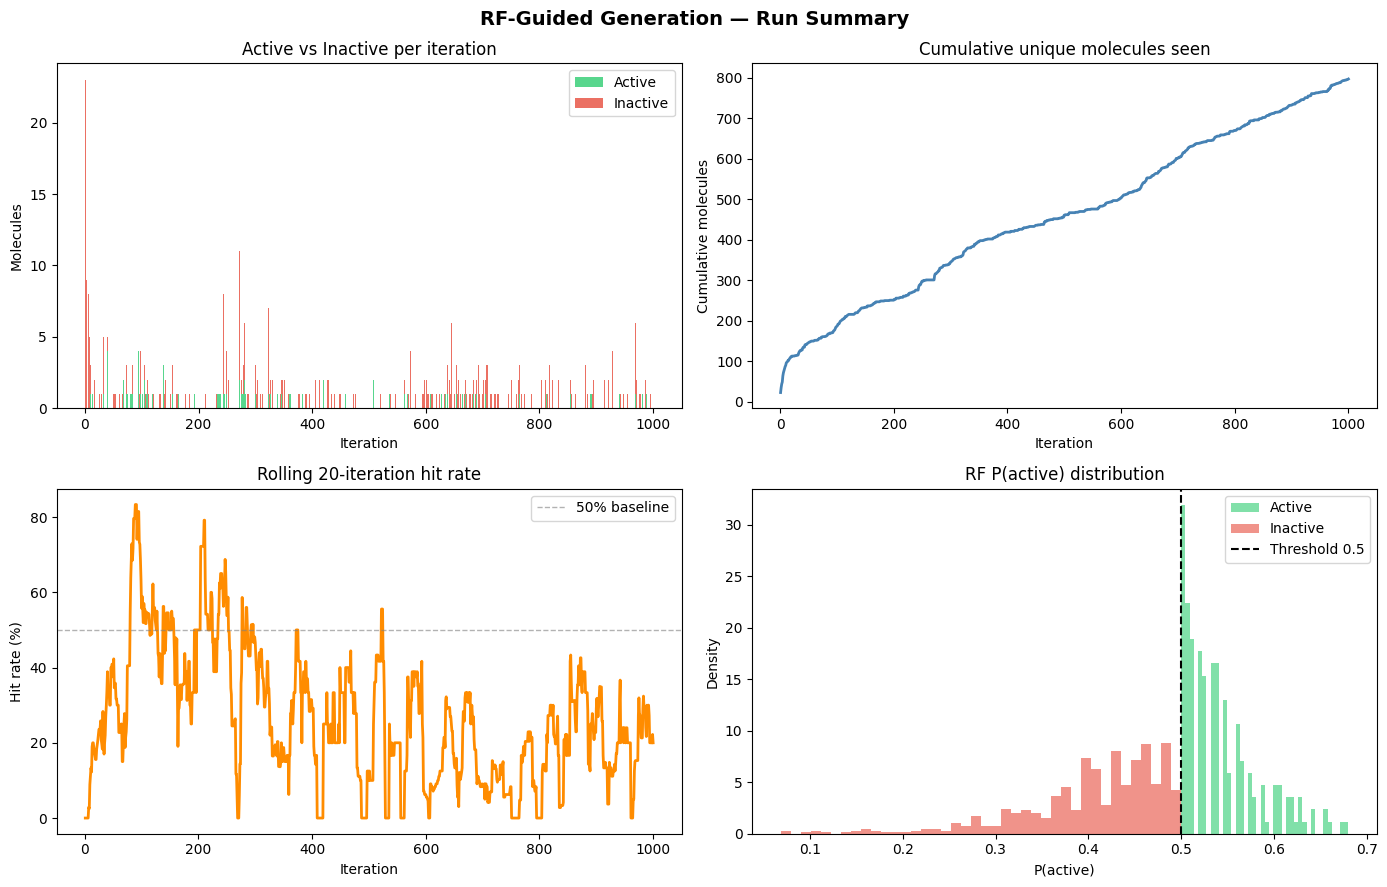

Summary plots saved to rf_guided_run_summary.png


In [13]:
# ── Post-run analysis ─────────────────────────────────────────────────────
import matplotlib.pyplot as plt

df_stats = pd.DataFrame(iter_stats)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Active vs Inactive per iteration
ax = axes[0, 0]
ax.bar(df_stats['iteration'], df_stats['n_active'],   label='Active',   color='#2ecc71', alpha=0.8)
ax.bar(df_stats['iteration'], df_stats['n_inactive'], label='Inactive', color='#e74c3c', alpha=0.8,
       bottom=df_stats['n_active'])
ax.set_xlabel('Iteration'); ax.set_ylabel('Molecules')
ax.set_title('Active vs Inactive per iteration')
ax.legend()

# 2. Cumulative total seen
ax = axes[0, 1]
ax.plot(df_stats['iteration'], df_stats['n_total_seen'], color='steelblue', lw=2)
ax.set_xlabel('Iteration'); ax.set_ylabel('Cumulative molecules')
ax.set_title('Cumulative unique molecules seen')

# 3. Hit rate (rolling 20-iter average)
ax = axes[1, 0]
total_per_iter = df_stats['n_passed_filters'].replace(0, np.nan)
hit_rate_iter  = df_stats['n_active'] / total_per_iter * 100
rolling_hr     = hit_rate_iter.rolling(20, min_periods=1).mean()
ax.plot(df_stats['iteration'], rolling_hr, color='darkorange', lw=2)
ax.axhline(50, color='gray', linestyle='--', lw=1, alpha=0.6, label='50% baseline')
ax.set_xlabel('Iteration'); ax.set_ylabel('Hit rate (%)')
ax.set_title('Rolling 20-iteration hit rate')
ax.legend()

# 4. RF P(active) distribution — Active vs Inactive
ax = axes[1, 1]
if 'rf_p_active' in df_all.columns:
    for lbl, col in [('Active', '#2ecc71'), ('Inactive', '#e74c3c')]:
        sub = df_all[df_all['rf_label'] == lbl]['rf_p_active']
        ax.hist(sub, bins=40, alpha=0.6, color=col, label=lbl, density=True)
    ax.axvline(RF_ACTIVE_THRESHOLD, color='k', linestyle='--', lw=1.5,
               label=f'Threshold {RF_ACTIVE_THRESHOLD}')
    ax.set_xlabel('P(active)'); ax.set_ylabel('Density')
    ax.set_title('RF P(active) distribution')
    ax.legend()

plt.suptitle('RF-Guided Generation — Run Summary', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('rf_guided_run_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('Summary plots saved to rf_guided_run_summary.png')

In [14]:
# ── Top candidates ────────────────────────────────────────────────────────
# Top-10 actives ranked by P(active)
df_actives = df_all[df_all['rf_label'] == 'Active'].copy()
df_actives_sorted = df_actives.sort_values('rf_p_active', ascending=False)

print(f'Top 10 active candidates by RF P(active):')
cols_show = ['Structure', 'rf_p_active', 'molecularWeight', 'cLogP',
             'topologicalSurfaceArea', 'basicNitrogenCount', 'aromaticRingCount',
             'AMCS_passes', 'iteration']
cols_show = [c for c in cols_show if c in df_actives_sorted.columns]
display(df_actives_sorted[cols_show].head(10))

# Save top-10 separately
df_actives_sorted[cols_show].head(10).to_csv('top10_active_candidates.csv', index=False)
print('Top 10 saved to top10_active_candidates.csv')

# Scaffold frequency summary
print(f'\nTop 10 active scaffolds by frequency:')
sc_df = pd.DataFrame([
    {'scaffold': sc, 'active_count': cnt}
    for sc, cnt in sorted(scaffold_freq.items(), key=lambda x: x[1], reverse=True)
]).head(10)
display(sc_df)

Top 10 active candidates by RF P(active):


,Structure,rf_p_active,molecularWeight,cLogP,topologicalSurfaceArea,basicNitrogenCount,aromaticRingCount,AMCS_passes,iteration
291,CC1CN(Cc2cccc(C(=O)NC3CCN(c4cccc(Cc5cccnc5)c4)...,0.6800,483.658,3.683,60.50,2,3,4,248
261,CC1CN(Cc2cccc(C(=O)NCc3ccc(N4CCC(Cc5cccc(N6CCC...,0.6734,595.829,4.815,71.08,2,3,4,222
163,CC1CN(Cc2cccc(CC(O)C3CCN(c4cccc(C(=O)Nc5ccc(C(...,0.6593,554.776,5.744,67.84,2,3,4,83
94,CCN1CCN(Cc2ccc(NC(=O)c3cccc(C(=O)N4CCCNC(C)C4)...,0.6541,463.624,3.112,67.92,3,2,4,11
193,CNC(=O)Cc1cccc(NC(=O)c2cc(CN3CCC(C(O)Cc4cccc(N...,0.6533,719.928,4.940,134.16,2,4,3,105
200,CC1CN(Cc2cccc(C(O)C3CCN(c4cccc(NC(=O)c5ccc(CN6...,0.6403,610.844,3.756,74.32,4,3,4,108
194,CNC(=O)c1cc(CN2CCC(Cc3cccc(N4CCC(Cc5ccc(CN6CCN...,0.6400,795.445,5.758,105.73,3,4,3,105
273,CNC(=O)c1cc(CN2CCC(Cc3cccc(N4CCC(Cc5ccc(O)c(CN...,0.6333,788.046,6.254,124.51,2,4,3,238
491,CC1CN(Cc2cccc(C(=O)Nc3cc(N4CCC(Cc5cccc(O)c5)CC...,0.6267,517.647,4.230,80.73,2,3,3,576
160,CC(C)OCCC1(C)CN(c2cc(CC3(O)CCN(c4cccc(C(=O)Nc5...,0.6267,683.939,4.449,96.44,4,3,3,75


Top 10 saved to top10_active_candidates.csv

Top 10 active scaffolds by frequency:


,scaffold,active_count
0,c1ccc(Nc2ccc(CN3CCCCC3)cn2)cc1,3
1,c1ccc(Nc2ccc(CN3CCC(CCc4cccc(N5CCNCC5)c4)CC3)c...,2
2,O=C(Nc1cccc(CN2CCNCC2)c1)c1ccc(C2CCNC(Cc3cccnc...,2
3,c1cncc(CN2CCC(Cc3cccc(N4CCNC(Cc5ccsc5)C4)c3)CC...,2
4,c1cncc(CC2CCN(c3cccc(CC4CCN(Cc5cccnc5)CC4)c3)C...,2
5,O=C(Nc1ccc(CN2CCNCC2)cc1)c1ccc(C(=O)N2CCCC2)cc1,1
6,O=C(Nc1ccc(CN2CCNCC2)cc1)c1cccnc1,1
7,O=C(c1ccccc1)c1cncc(N2CCCC2)c1,1
8,O=C(Nc1ccc(CN2CCNCC2)cc1)c1cncc(N2CCCCC2)c1,1
9,O=C(Nc1ccc(CN2CCNCC2)cc1)c1cccc(C(=O)N2CCCNCC2)c1,1
